# Wavelet Image Denoising: Sparsity Across Scales

**Question:** can a multiscale representation help remove noise while preserving useful structure?

The [previous study](01_time_frequency_analysis.ipynb) exposed the limitations of one fixed window. Wavelets use scale-dependent analysis and represent smooth regions and localized transitions differently. This study examines 1D wavelet families, 2D directional subbands, filtering, and hard-threshold denoising with both decimated and stationary transforms.

The algorithmic experiments come from the original course project. The original boat image and chessboard resource are included in `data/images/`. Reproducible exports and a consolidated comparison connect the original experiments.

In [1]:
from pathlib import Path
import sys
import numpy as np
from IPython.display import display, Markdown, Image, Audio

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src/signal_inverse").is_dir():
    raise RuntimeError("Open this notebook from the repository root or notebooks directory.")
sys.path.insert(0, str(ROOT / "src"))
from signal_inverse.datasets import load_inputs
from signal_inverse.experiments import run_wavelets

inputs = load_inputs(ROOT / "data")
output = ROOT / "results" / "wavelets"

def figure(name):
    display(Image(filename=str(output / (name + ".png")), width=1000))

def table(rows, columns):
    lines = ["| " + " | ".join(columns) + " |", "| " + " | ".join(["---"] * len(columns)) + " |"]
    for row in rows:
        values = [f"{row[c]:.3f}" if isinstance(row[c], (float, np.floating)) else str(row[c]) for c in columns]
        lines.append("| " + " | ".join(values) + " |")
    display(Markdown("\n".join(lines)))

print("Inputs: original course image and recordings bundled in data/.")

Inputs: original course image and recordings bundled in data/.


## 1. Approximation and details

A multilevel decomposition writes a signal as a coarse approximation plus details at successively finer scales. In PyWavelets the coefficient ordering is $[cA_J,cD_J,\ldots,cD_1]$.

Haar is suited to piecewise-constant structure; longer filters can represent smoother behavior differently and also introduce boundary effects. The family comparison is qualitative: it does not establish a universally best wavelet.

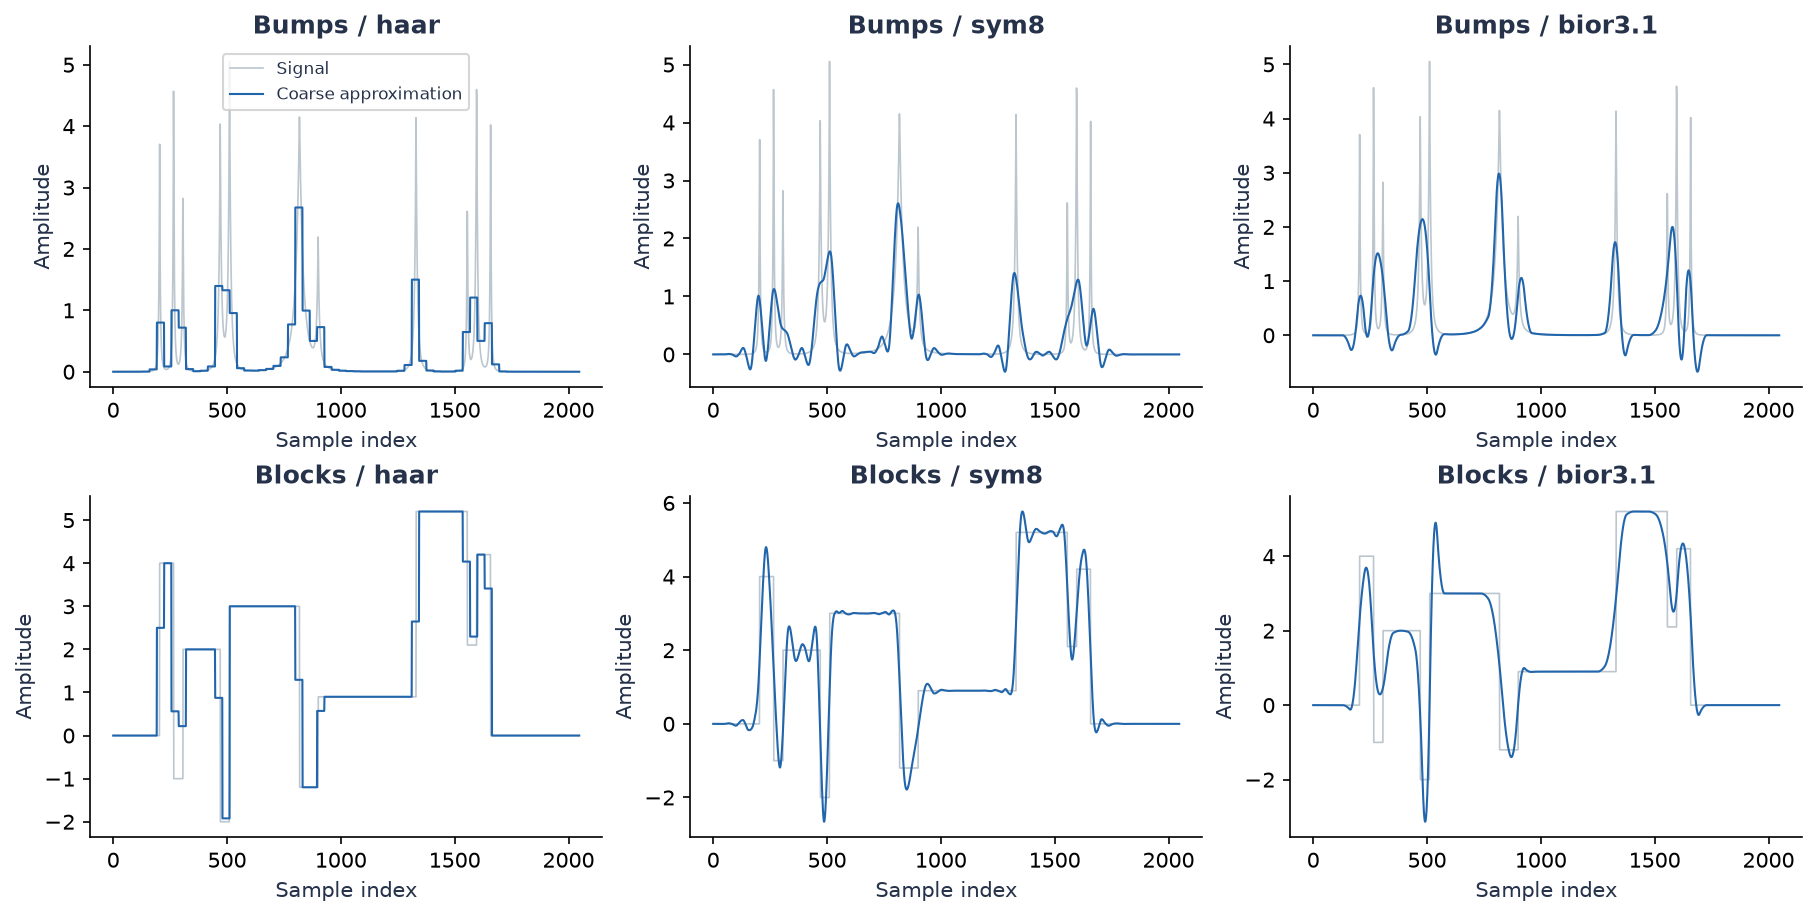

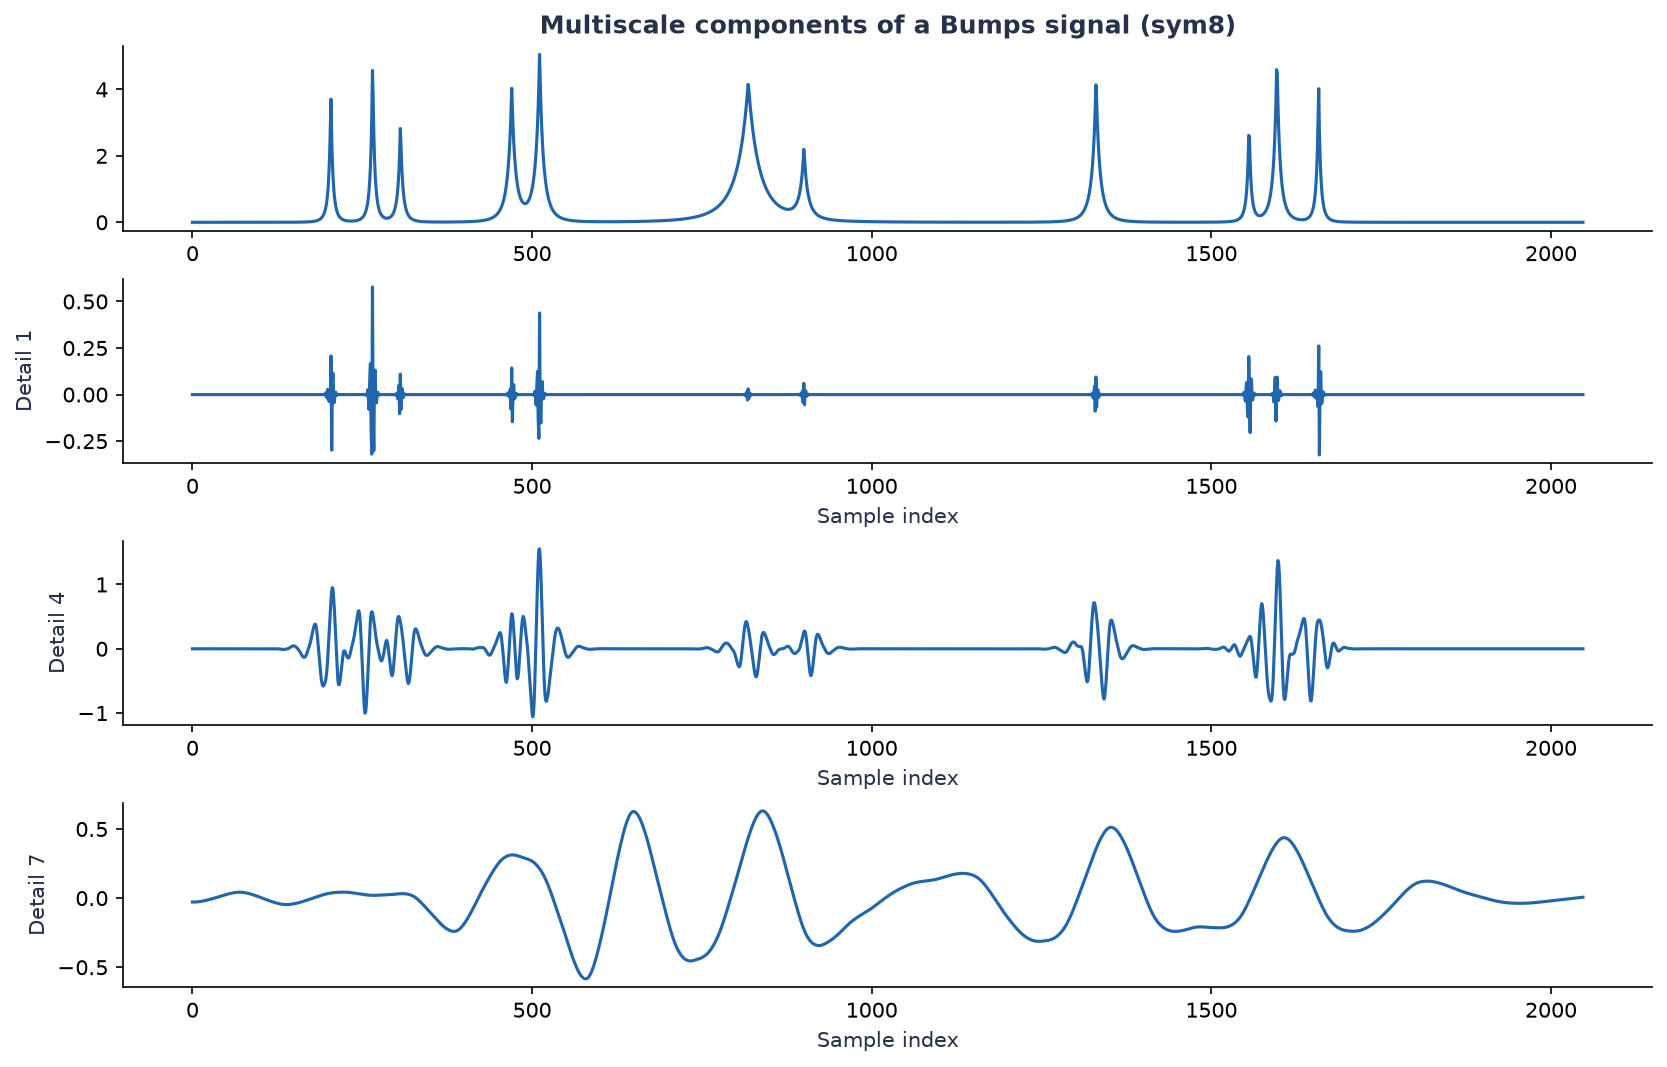

In [2]:
report = run_wavelets(inputs, output)
figure("wavelet_families")
figure("detail_scales")

## 2. Moving to images

The 2D transform separates a coarse approximation and three detail orientations at each level. Directional filtering demonstrates what changes when a subband is suppressed. The directions follow PyWavelets' axis convention; they should not be inferred solely from where a coefficient block appears in a plot.

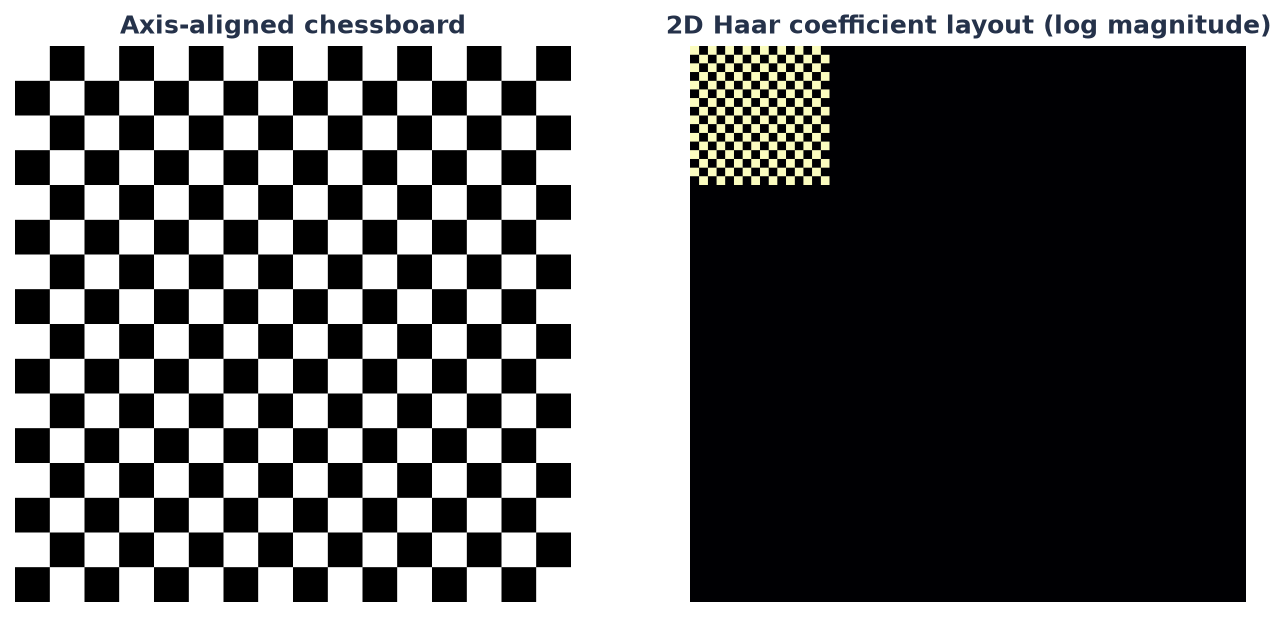

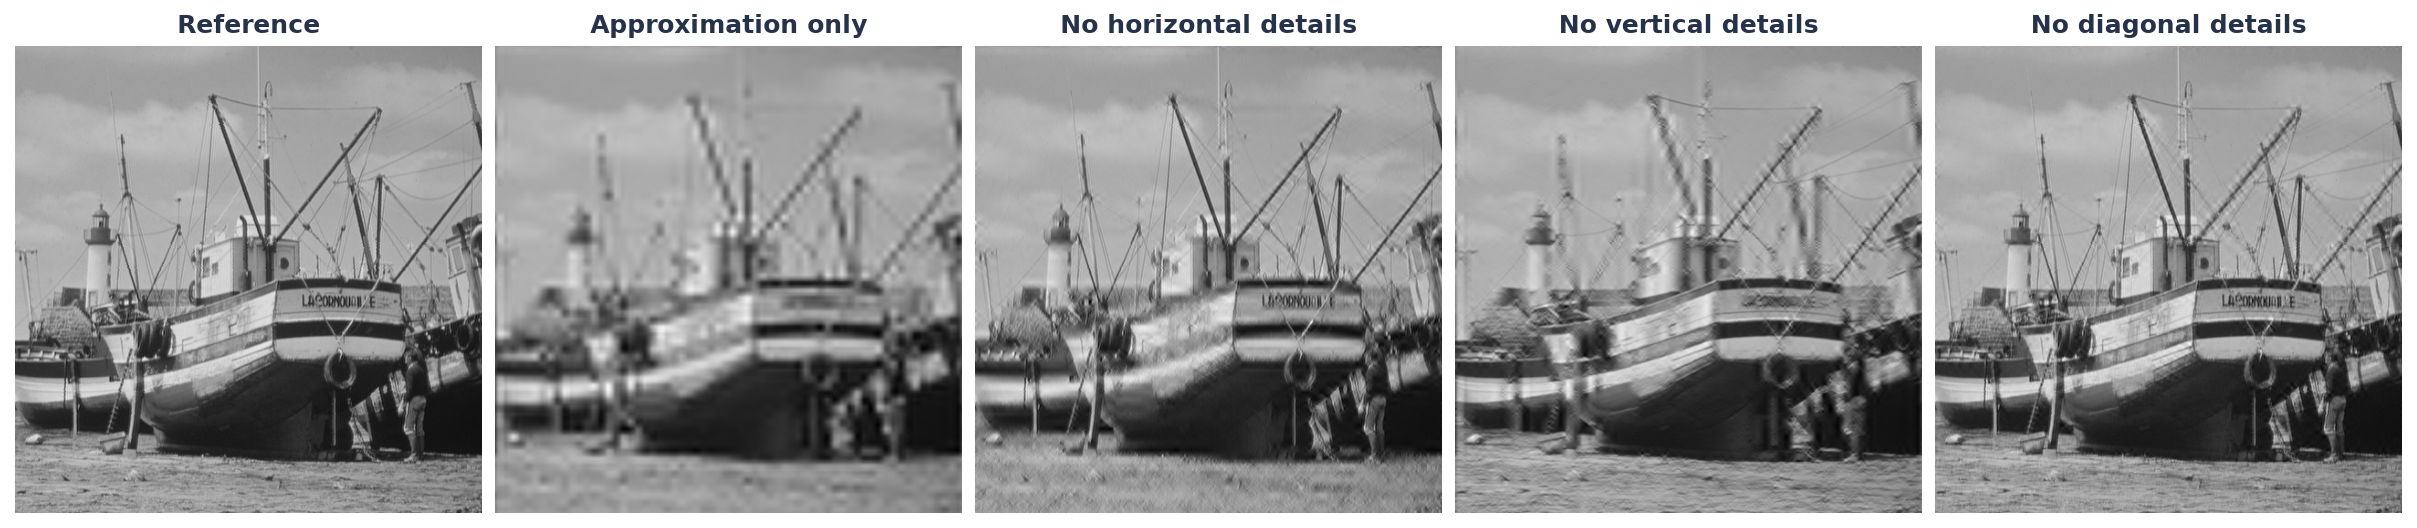

In [3]:
figure("coefficient_layout")
figure("directional_filtering")

## 3. A sparse-representation prior

The observation model is $y=x+\varepsilon$ with independent Gaussian noise of standard deviation $\sigma=0.1$ on the $[0,1]$ image scale. Hard thresholding applies

$$H_t(c)=c\,\mathbf{1}_{|c|>t}.$$

The approximation is preserved; only detail coefficients are thresholded. The sweep uses levels 1 through 5 and thresholds 0.1, 0.2, 0.3 and 0.4, matching the original experiment. One seeded noise realization is reused across all configurations.

DWT uses periodic extension. SWT is redundant and uses `norm=False`, as in the original lab. We reconstruct using the matching inverse transform. Scores are computed **before clipping**, with a fixed PSNR range of one:

$$\operatorname{PSNR}(x,\hat x)=10\log_{10}\frac{1}{\operatorname{MSE}(x,\hat x)}.$$

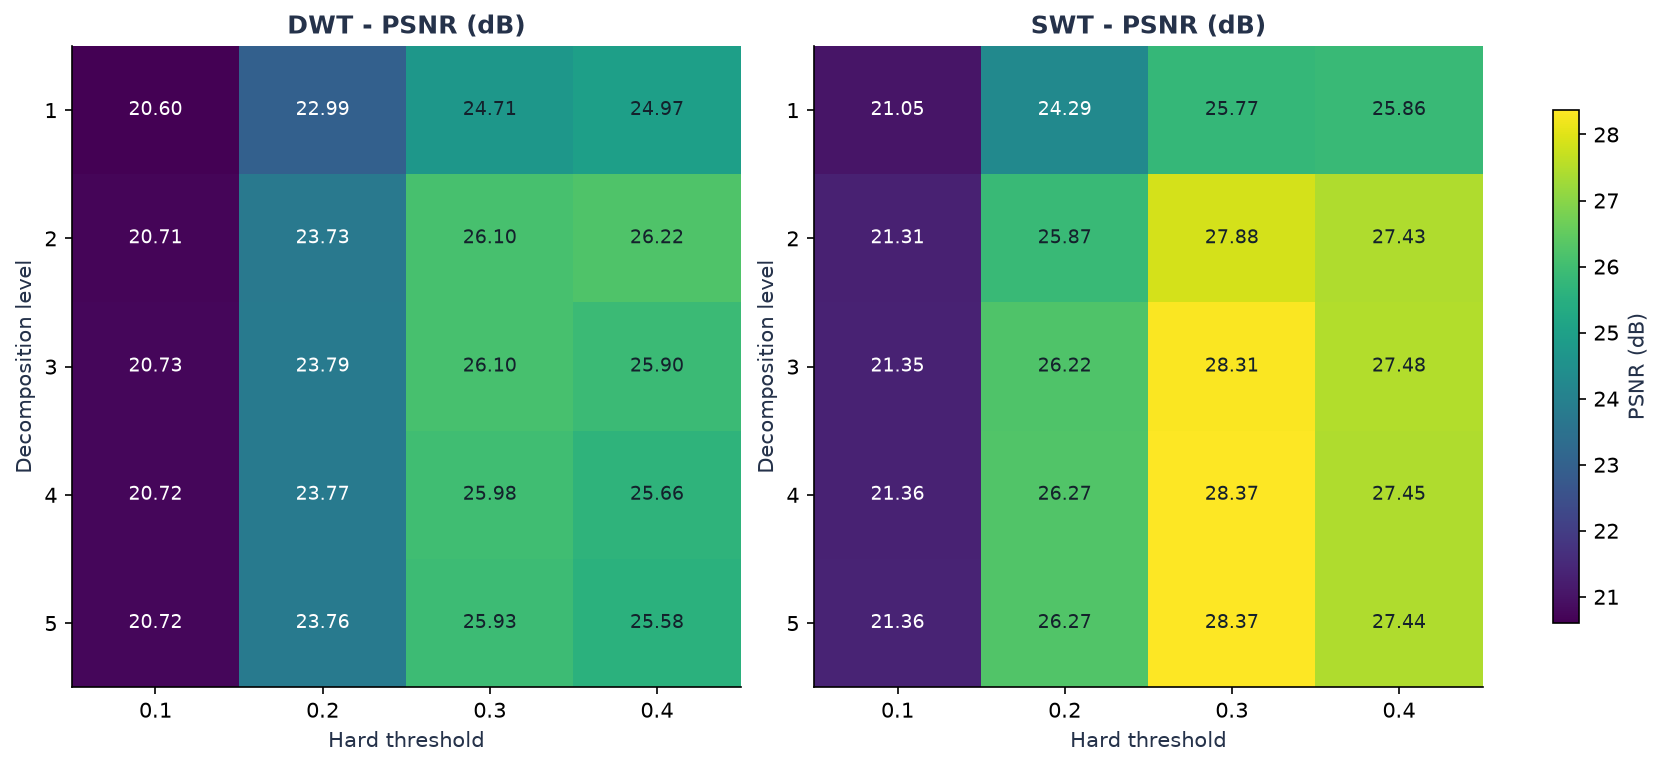

| transform | wavelet | level | threshold | psnr_db |
| --- | --- | --- | --- | --- |
| dwt | sym8 | 2 | 0.400 | 26.225 |
| swt | sym8 | 5 | 0.300 | 28.369 |

In [4]:
figure("threshold_heatmaps")
table(list(report["best"].values()), ["transform", "wavelet", "level", "threshold", "psnr_db"])

## 4. Interpreting the comparison

Small thresholds retain more noise; excessive thresholds erase useful coefficients. SWT avoids decimation and is more translation-invariant under its periodic convention, at the cost of additional memory and computation. Neither method is a learned model.

The highlighted configuration is an **oracle choice on the known clean reference**. It describes this experiment, not unseen-data performance or an automatic threshold-selection procedure. A threshold sweep is analysis, not a training/test evaluation.

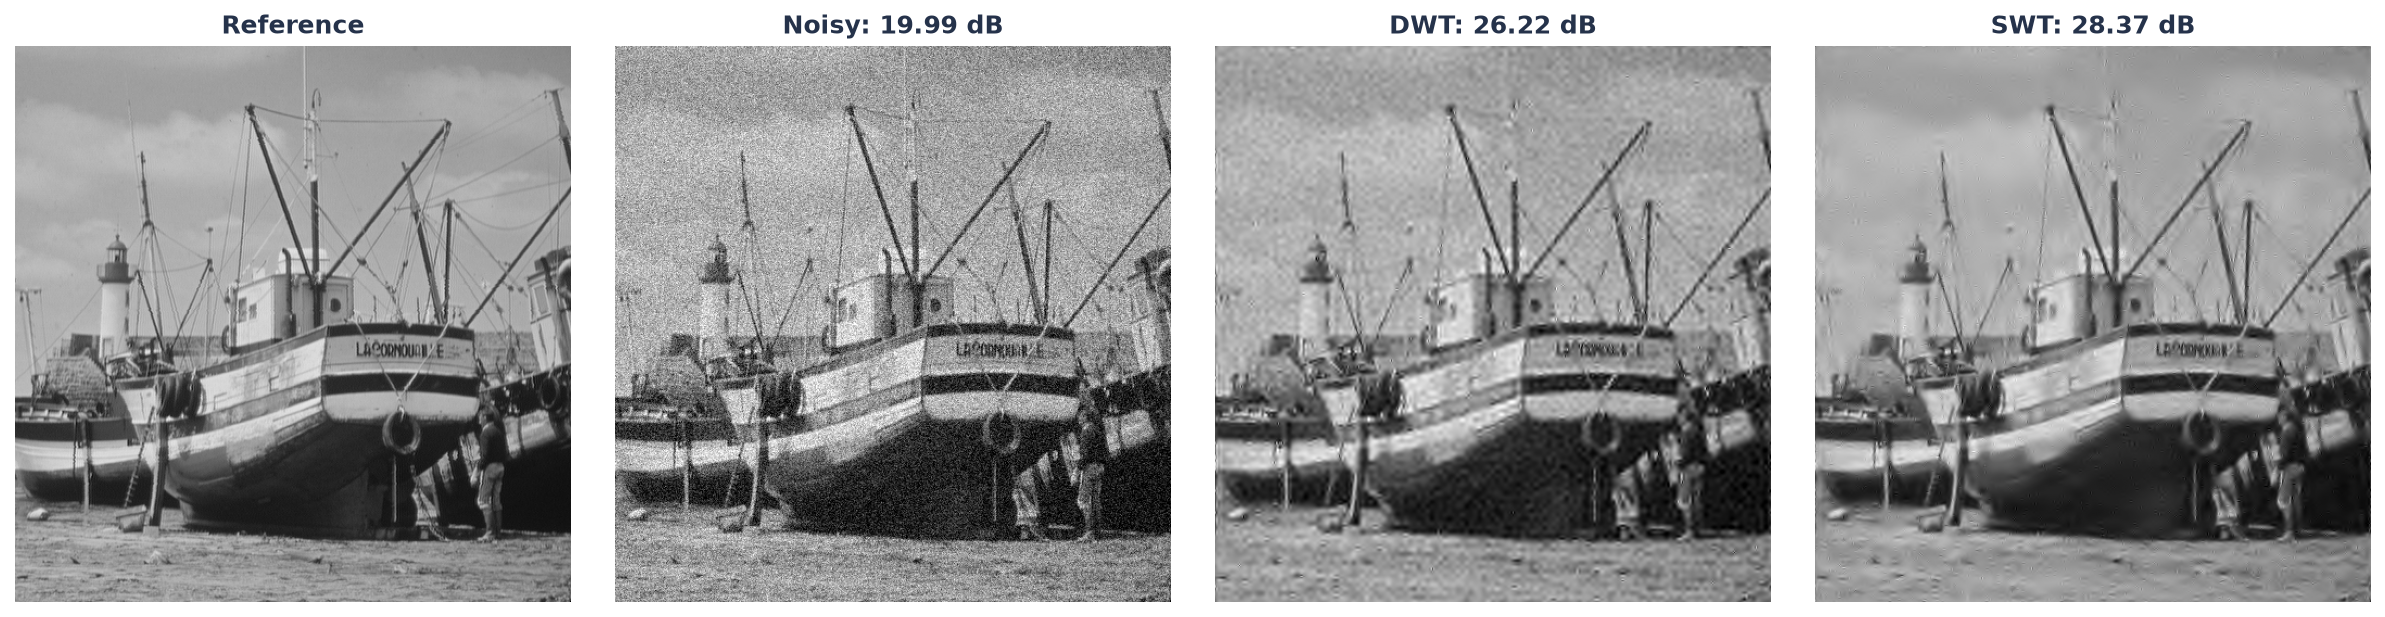

DWT: 26.22 dB, gain over noisy input +6.24 dB
SWT: 28.37 dB, gain over noisy input +8.38 dB


In [5]:
figure("denoising_comparison")
for name, best in report["best"].items():
    print(f"{name.upper()}: {best['psnr_db']:.2f} dB, gain over noisy input {best['psnr_db']-report['noisy_psnr_db']:+.2f} dB")

## 5. Inspect the reusable implementation

The exported implementation keeps approximation/detail handling explicit rather than manipulating packed coefficient arrays. Zero-threshold reconstruction, approximation preservation and sum-of-components checks are covered by numerical tests.

In [6]:
import inspect
from signal_inverse.wavelets import denoise
print(inspect.getsource(denoise))

def denoise(image, threshold, level=3, wavelet="sym8", transform="dwt"):
    """Preserve the coarse approximation, threshold every detail subband.

    DWT uses periodic boundary extension. SWT is unnormalized, matching the
    convention in the supplied implementation; threshold scales are unchanged.
    No post-reconstruction clipping is applied to the scored output.
    """
    image = np.asarray(image, dtype=float)
    if image.ndim != 2 or level < 1:
        raise ValueError("A 2D image and a positive decomposition level are required.")
    if transform == "dwt":
        max_level = pywt.dwtn_max_level(image.shape, wavelet)
        if level > max_level:
            raise ValueError(f"level {level} exceeds the boundary-safe maximum {max_level}.")
        coeffs = pywt.wavedec2(image, wavelet, mode="periodization", level=level)
        filtered = [coeffs[0]] + [tuple(hard_threshold(d, threshold) for d in detail) for detail in coeffs[1:]]
        result = pywt.waverec2(filtered, wave

## Findings and limits

Thresholding works because signal structure and Gaussian noise have different coefficient distributions, not because every small coefficient is noise. Fine texture can be lost along with noise, and periodization can affect borders. Results depend on the image, noise level and one seeded realization.

**Connection:** [audio source separation](03_sparse_source_separation.ipynb) also exploits sparsity, but to disentangle overlapping sources rather than to suppress small coefficients. [Image restoration](04_optimization_image_restoration.ipynb) makes a different prior explicit through an optimization objective.

**References:** [PyWavelets multilevel transforms](https://pywavelets.readthedocs.io/en/latest/regression/multilevel.html), [stationary wavelet transform](https://pywavelets.readthedocs.io/en/latest/ref/swt-stationary-wavelet-transform.html), and [project bibliography](../REFERENCES.md).